# Lab 3: Gesture Recognition using Convolutional Neural Networks

In this lab you will train a convolutional neural network to make classifications on different hand gestures. By the end of the lab, you should be able to:

1. Load and split data for training, validation and testing
2. Train a Convolutional Neural Network
3. Apply transfer learning to improve your model

Note that for this lab we will not be providing you with any starter code. You should be able to take the code used in previous labs, tutorials and lectures and modify it accordingly to complete the tasks outlined below.

### What to submit

Submit a PDF file containing all your code, outputs, and write-up
from parts 1-5. You can produce a PDF of your Google Colab file by
going to **File > Print** and then save as PDF. The Colab instructions
has more information. Make sure to review the PDF submission to ensure that your answers are easy to read. Make sure that your text is not cut off at the margins. 

**Do not submit any other files produced by your code.**

Include a link to your colab file in your submission.

Please use Google Colab to complete this assignment. If you want to use Jupyter Notebook, please complete the assignment and upload your Jupyter Notebook file to Google Colab for submission. 

## Colab Link

Include a link to your colab file here

Colab Link: 

## Dataset

American Sign Language (ASL) is a complete, complex language that employs signs made by moving the
hands combined with facial expressions and postures of the body. It is the primary language of many
North Americans who are deaf and is one of several communication options used by people who are deaf or
hard-of-hearing. The hand gestures representing English alphabet are shown below. This lab focuses on classifying a subset
of these hand gesture images using convolutional neural networks. Specifically, given an image of a hand
showing one of the letters A-I, we want to detect which letter is being represented.

![alt text](https://www.disabled-world.com/pics/1/asl-alphabet.jpg)

## Part B. Building a CNN [50 pt]

For this lab, we are not going to give you any starter code. You will be writing a convolutional neural network
from scratch. You are welcome to use any code from previous labs, lectures and tutorials. You should also
write your own code.

You may use the PyTorch documentation freely. You might also find online tutorials helpful. However, all
code that you submit must be your own.

Make sure that your code is vectorized, and does not contain obvious inefficiencies (for example, unecessary
for loops, or unnecessary calls to unsqueeze()). Ensure enough comments are included in the code so that
your TA can understand what you are doing. It is your responsibility to show that you understand what you
write.

**This is much more challenging and time-consuming than the previous labs.** Make sure that you
give yourself plenty of time by starting early.

### 1. Data Loading and Splitting [5 pt]

Download the anonymized data provided on Quercus. To allow you to get a heads start on this project we will provide you with sample data from previous years. Split the data into training, validation, and test sets.

Note: Data splitting is not as trivial in this lab. We want our test set to closely resemble the setting in which
our model will be used. In particular, our test set should contain hands that are never seen in training!

Explain how you split the data, either by describing what you did, or by showing the code that you used.
Justify your choice of splitting strategy. How many training, validation, and test images do you have?

For loading the data, you can use plt.imread as in Lab 1, or any other method that you choose. You may find
torchvision.datasets.ImageFolder helpful. (see https://pytorch.org/docs/stable/torchvision/datasets.html?highlight=image%20folder#torchvision.datasets.ImageFolder
) 

In [3]:
# Load the dataset (paths + labels only) 
import os
import re
import random
from collections import Counter

import torch
import torchvision
from torchvision import datasets, transforms

# Path to the folder that contains the A/ ... I/ subfolders,
# relative to this notebook's folder (the "Lab 3" folder).
DATA_DIR = 'Lab3 Dataset/Lab3_Gestures_Summer'

# ImageFolder uses each subfolder name (A-I) as the class label.
# It only stores (file path, label) pairs here; pixels are read from disk
# lazily, one image at a time, when the dataset is indexed later.
# ToTensor is a generic conversion (pixels -> float tensor in [0, 1]);
# any model-specific preprocessing will be added in later parts.
full_dataset = datasets.ImageFolder(DATA_DIR, transform=transforms.ToTensor())

classes = full_dataset.classes          # ['A', 'B', ..., 'I']
samples = full_dataset.samples          # list of (path, class_index)
print('Classes:', classes)
print('Total images:', len(samples))


Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']
Total images: 2219


In [4]:
# Work out which physical hand each image comes from 
# Every filename looks like  <N>_<letter>_<view>.jpg , e.g. 28_A_2.jpg
# Checking all files shows the number N always follows this rule:
#     N = 27 * hand_id + 3 * letter_index + (view - 1)
# i.e. each contributor's hand owns a block of 27 numbers
# (9 letters x 3 views). So hand_id = N // 27 identifies the same hand
# across ALL letters, not just the 2-3 views of a single letter.
FILENAME_PATTERN = re.compile(r'^(\d+)_([A-I])_(\d+)\.jpg$')
IMAGES_PER_HAND_BLOCK = 27   # 9 letters x 3 views

hand_ids = []   # hand_ids[i] is the hand that image i belongs to
for path, label in samples:
    match = FILENAME_PATTERN.match(os.path.basename(path))
    if match is None:
        raise ValueError(f'Unexpected filename format: {path}')
    number, letter, view = int(match.group(1)), match.group(2), int(match.group(3))

    # Sanity checks: stop if any file breaks the assumed naming rule,
    # rather than silently grouping it wrongly.
    if letter != classes[label]:
        raise ValueError(f'Letter in filename does not match its folder: {path}')
    if number % IMAGES_PER_HAND_BLOCK != 3 * classes.index(letter) + (view - 1):
        raise ValueError(f'Filename does not follow the numbering rule: {path}')

    hand_ids.append(number // IMAGES_PER_HAND_BLOCK)

images_per_hand = Counter(hand_ids)
print('Number of distinct hands:', len(images_per_hand))
print('Letters covered per hand (count of hands):',
      dict(Counter(len({classes[samples[i][1]] for i, h in enumerate(hand_ids) if h == hand})
                   for hand in images_per_hand)))


Number of distinct hands: 88
Letters covered per hand (count of hands): {9: 80, 6: 1, 5: 2, 1: 3, 8: 2}


In [5]:
# Split by HAND (not by individual image) 
SEED = 42                     # fixed seed -> the same split every run
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # test gets the remaining ~15%

# Shuffle the list of hands (sorted first so the result doesn't depend
# on file-system ordering).
unique_hands = sorted(images_per_hand)
rng = random.Random(SEED)
rng.shuffle(unique_hands)

# Walk through the shuffled hands and give each WHOLE hand to one split:
# fill training until it reaches 70% of all images, then validation
# until train+val reaches 85%, and put the rest in test.
total = len(samples)
hand_to_split = {}
n_train = n_val = 0
for hand in unique_hands:
    if n_train < TRAIN_FRAC * total:
        hand_to_split[hand] = 'train'
        n_train += images_per_hand[hand]
    elif n_train + n_val < (TRAIN_FRAC + VAL_FRAC) * total:
        hand_to_split[hand] = 'val'
        n_val += images_per_hand[hand]
    else:
        hand_to_split[hand] = 'test'

# Turn the hand-level assignment into image indices for each split.
split_indices = {'train': [], 'val': [], 'test': []}
for idx, hand in enumerate(hand_ids):
    split_indices[hand_to_split[hand]].append(idx)


In [6]:
# Verify the split
hands_in = {name: {hand_ids[i] for i in idx} for name, idx in split_indices.items()}

print('Split   Images   % of total   Hands')
for name, idx in split_indices.items():
    print(f'{name:6s} {len(idx):7d} {100 * len(idx) / total:11.1f}% {len(hands_in[name]):7d}')
print(f'Total  {total:7d}')

print('\nImages per class:')
print('       ' + ''.join(f'{c:>5s}' for c in classes))
for name, idx in split_indices.items():
    counts = Counter(samples[i][1] for i in idx)
    print(f'{name:6s} ' + ''.join(f'{counts[k]:5d}' for k in range(len(classes))))

# Leakage check: the sets of hand IDs must not overlap.
overlaps = {
    'train & val':  hands_in['train'] & hands_in['val'],
    'train & test': hands_in['train'] & hands_in['test'],
    'val & test':   hands_in['val'] & hands_in['test'],
}
for pair, shared in overlaps.items():
    if shared:
        raise RuntimeError(f'Data leakage! Hands shared by {pair}: {sorted(shared)}')

# Every image must be used exactly once.
all_indices = sorted(split_indices['train'] + split_indices['val'] + split_indices['test'])
if all_indices != list(range(total)):
    raise RuntimeError('Some images are missing from, or repeated across, the splits.')

print('\nVerified: train/val/test hand IDs are disjoint and every image is used exactly once.')


Split   Images   % of total   Hands
train     1562        70.4%      62
val        345        15.5%      13
test       312        14.1%      13
Total     2219

Images per class:
           A    B    C    D    E    F    G    H    I
train    180  174  172  172  172  168  177  171  176
val       37   39   39   39   39   35   39   39   39
test      37   34   34   36   36   33   34   34   34

Verified: train/val/test hand IDs are disjoint and every image is used exactly once.


In [7]:
# PyTorch datasets for later parts 
# Subset just stores the indices; images are still loaded lazily from disk.
from torch.utils.data import Subset

train_dataset = Subset(full_dataset, split_indices['train'])
val_dataset   = Subset(full_dataset, split_indices['val'])
test_dataset  = Subset(full_dataset, split_indices['test'])

print('train:', len(train_dataset), ' val:', len(val_dataset), ' test:', len(test_dataset))
image, label = train_dataset[0]
print('Example image tensor shape:', tuple(image.shape), ' label:', classes[label])


train: 1562  val: 345  test: 312
Example image tensor shape: (3, 224, 224)  label: A


**How the data was split**

The images are organized into one folder per letter (A–I), and each file is named `<N>_<letter>_<view>.jpg`. Checking every file showed that the number follows a fixed rule: `N = 27 × hand + 3 × letter_index + (view − 1)`. In other words, each contributor's hand owns a block of 27 consecutive numbers (9 letters × up to 3 views), so `N // 27` identifies the same physical hand across **all** letters, not just the 2–3 views of one letter. The code checks that every filename follows this rule and stops with an error if one doesn't. In total there are 2,219 images from 88 hands, and 80 of those hands contributed all nine letters.

I split the data **by hand** instead of by image. With a fixed seed (42), the 88 hands are shuffled. Whole hands are then added to the training set until it holds about 70% of the images, then to the validation set until train + validation hold about 85%. The remaining hands form the test set. Every image of a given hand, for every letter and every angle, ends up in exactly one split. The code checks that the hand IDs in the three splits do not overlap and raises an error if they do.

If the images were split at random, different angles of the same hand (or the same person's other letters) would appear in both training and test. The model could then score well by recognizing the person's hand, skin tone, or background instead of the gesture, which would make the test accuracy too optimistic. The validation set is kept hand-disjoint for the same reason, so that hyperparameter choices are based on how well the model generalizes to new people.

**Result:**

| Split | Images | % of total | Hands |
|---|---|---|---|
| Training | 1562 | 70.4% | 62 |
| Validation | 345 | 15.5% | 13 |
| Test | 312 | 14.1% | 13 |
| **Total** | **2219** | | **88** |

Because whole hands must stay together, the proportions cannot be exactly 70/15/15; each hand moves about 27 images at once. Most hands contributed all nine letters, so each split stays roughly balanced across classes (about 168–180 training images per letter, 35–39 validation, and 33–37 test).


### 2. Model Building and Sanity Checking [15 pt]

### Part (a) Convolutional Network - 5 pt

Build a convolutional neural network model that takes the (224x224 RGB) image as input, and predicts the gesture
letter. Your model should be a subclass of nn.Module. Explain your choice of neural network architecture: how
many layers did you choose? What types of layers did you use? Were they fully-connected or convolutional?
What about other decisions like pooling layers, activation functions, number of channels / hidden units?

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class GestureCNN(nn.Module):
    """
    CNN for classifying 224x224 RGB images of ASL letters A-I (9 classes).

    Structure (same pattern as LargeNet from Lab 2 / Lecture 4, but deeper
    because our images are 224x224 instead of 32x32):
        4 x [ Conv2d (3x3, padding 1) -> ReLU -> MaxPool2d (2x2) ]
        -> flatten -> Linear -> ReLU -> Linear (9 outputs)

    base_channels and hidden_units are arguments so they are easy to change
    during hyperparameter tuning later.
    """
    def __init__(self, base_channels=8, hidden_units=64):
        super(GestureCNN, self).__init__()
        self.name = "cnn"   # used later for checkpoint file names 

        # Number of output channels for each conv layer. The number of channels
        # doubles every layer while the image size halves 
        c1, c2, c3, c4 = base_channels, base_channels * 2, base_channels * 4, base_channels * 8

        # Convolutional layers: nn.Conv2d(in_channels, out_channels, kernel_size, padding)
        # A 3x3 kernel with padding=1 ("half padding") keeps the height and width
        # the same:  o = (i + 2p - k)/s + 1 = (i + 2 - 3)/1 + 1 = i
        self.conv1 = nn.Conv2d(3,  c1, kernel_size=3, padding=1)   # 3 input channels = RGB
        self.conv2 = nn.Conv2d(c1, c2, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(c2, c3, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(c3, c4, kernel_size=3, padding=1)

        # One max pooling layer reused after every conv layer.
        # kernel 2, stride 2 halves the height and width:  o = (i - 2)/2 + 1 = i/2
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Size of the flattened feature map going into the first fully connected layer.
        # Height/width after the 4 pooling layers: 224 -> 112 -> 56 -> 28 -> 14
        # so the last feature map is [c4, 14, 14]  ->  c4 * 14 * 14 values per image.
        self.flat_size = c4 * 14 * 14     # = 64 * 14 * 14 = 12544 with the defaults

        # Fully connected (classifier) layers
        self.fc1 = nn.Linear(self.flat_size, hidden_units)
        self.fc2 = nn.Linear(hidden_units, 9)   # one output per letter A-I

    def forward(self, x):
        # x: [N, 3, 224, 224]
        x = self.pool(F.relu(self.conv1(x)))   # conv -> [N, c1, 224, 224], pool -> [N, c1, 112, 112]
        x = self.pool(F.relu(self.conv2(x)))   # conv -> [N, c2, 112, 112], pool -> [N, c2, 56, 56]
        x = self.pool(F.relu(self.conv3(x)))   # conv -> [N, c3, 56, 56],   pool -> [N, c3, 28, 28]
        x = self.pool(F.relu(self.conv4(x)))   # conv -> [N, c4, 28, 28],   pool -> [N, c4, 14, 14]
        x = x.view(-1, self.flat_size)         # flatten -> [N, c4*14*14]
        x = F.relu(self.fc1(x))                # -> [N, hidden_units]
        x = self.fc2(x)                        # -> [N, 9]
        # No softmax here: we return raw scores (logits). nn.CrossEntropyLoss
        # applies softmax internally (Lecture 3). To get probabilities later,
        # use F.softmax(output, dim=1).
        return x


In [9]:
# Sanity check: pass a dummy batch through the model (no training).
model = GestureCNN()
dummy = torch.randn(4, 3, 224, 224)          # batch of N=4 random "images"

# Print the shape after every layer to confirm the calculations above.
x = dummy
print('input        ', tuple(x.shape))
for i, conv in enumerate([model.conv1, model.conv2, model.conv3, model.conv4], start=1):
    x = F.relu(conv(x));  print(f'conv{i} + relu ', tuple(x.shape))
    x = model.pool(x);    print(f'pool{i}        ', tuple(x.shape))
x = x.view(-1, model.flat_size);  print('flatten      ', tuple(x.shape))
x = F.relu(model.fc1(x));         print('fc1 + relu   ', tuple(x.shape))
x = model.fc2(x);                 print('fc2 (output) ', tuple(x.shape))

# The full forward pass should give one score per class for each image.
out = model(dummy)
assert out.shape == (4, 9), f'Expected (4, 9), got {tuple(out.shape)}'

# It should also work on a real image from the training set.
image, label = train_dataset[0]
print('Real image output shape:', tuple(model(image.unsqueeze(0)).shape))

num_params = sum(p.numel() for p in model.parameters())
print('Total trainable parameters:', num_params)


input         (4, 3, 224, 224)
conv1 + relu  (4, 8, 224, 224)
pool1         (4, 8, 112, 112)
conv2 + relu  (4, 16, 112, 112)
pool2         (4, 16, 56, 56)
conv3 + relu  (4, 32, 56, 56)
pool3         (4, 32, 28, 28)
conv4 + relu  (4, 64, 28, 28)
pool4         (4, 64, 14, 14)
flatten       (4, 12544)
fc1 + relu    (4, 64)
fc2 (output)  (4, 9)
Real image output shape: (1, 9)
Total trainable parameters: 827993


**Architecture**

| Layer | Purpose | Output shape (N = batch size) |
|---|---|---|
| Input | RGB image | [N, 3, 224, 224] |
| Conv1 (3→8, 3×3, pad 1) + ReLU | low-level features (edges, colour changes) | [N, 8, 224, 224] |
| MaxPool (2×2, stride 2) | halve height/width | [N, 8, 112, 112] |
| Conv2 (8→16, 3×3, pad 1) + ReLU | combine edges into simple shapes | [N, 16, 112, 112] |
| MaxPool | halve height/width | [N, 16, 56, 56] |
| Conv3 (16→32, 3×3, pad 1) + ReLU | larger parts (finger/thumb shapes) | [N, 32, 56, 56] |
| MaxPool | halve height/width | [N, 32, 28, 28] |
| Conv4 (32→64, 3×3, pad 1) + ReLU | whole-hand features | [N, 64, 28, 28] |
| MaxPool | halve height/width | [N, 64, 14, 14] |
| Flatten | turn feature maps into a vector | [N, 12544] (= 64 × 14 × 14) |
| FC1 (12544→64) + ReLU | combine features | [N, 64] |
| FC2 (64→9) | one score (logit) per letter A–I | [N, 9] |

Sizes come from the output-size formula o = ⌊(i + 2p − k)/s⌋ + 1. For each conv: (i + 2 − 3)/1 + 1 = i, so the size stays the same. For each pool: (i − 2)/2 + 1 = i/2, so the size halves. Total trainable parameters: 827,993.

**Explanation**

The network has 6 weight layers: 4 convolutional layers followed by 2 fully connected layers. It follows the same convolution → ReLU → max pooling pattern as LargeNet from Lab 2, with two more convolutional layers because the input here is 224×224 instead of 32×32. Convolutional layers are used for feature extraction because a fully connected layer applied directly to a 3×224×224 image would need a very large number of weights and would ignore the spatial structure of the image. A convolutional filter reuses the same small set of weights at every position in the image.

All convolutions use 3×3 kernels with padding 1. With this padding, each convolution keeps the height and width unchanged, and each 2×2 max pool (stride 2) halves them: 224 → 112 → 56 → 28 → 14. This makes the feature map sizes easy to calculate. Small 3×3 kernels stacked over several layers can still respond to large regions of the image while using few weights, which is the approach used by VGG. Max pooling reduces computation, gives each later layer a wider view of the image, and makes the network less sensitive to small shifts in hand position.

The number of channels doubles at each layer (8 → 16 → 32 → 64) while the height and width halve. Early layers need only a few filters for simple features such as edges, and later layers need more filters to represent more complex combinations of them. Doubling the channels also stops the amount of information from shrinking too quickly as the image gets smaller. The last feature map (64 × 14 × 14 = 12,544 values) is flattened and passed to a fully connected hidden layer with 64 units, then to an output layer with 9 units, one per letter. ReLU is used after every layer except the last because it is simple and avoids the vanishing gradients of sigmoid. The output layer returns raw scores (logits) with no softmax, because `nn.CrossEntropyLoss` applies softmax internally.

The channel counts (8 to 64) and the 64 hidden units are kept small because there are only about 1,560 training images, which makes a larger network more likely to overfit and slower to train on a CPU. 

### Part (b) Training Code - 5 pt

Write code that trains your neural network given some training data. Your training code should make it easy
to tweak the usual hyperparameters, like batch size, learning rate, and the model object itself. Make sure
that you are checkpointing your models from time to time (the frequency is up to you). Explain your choice
of loss function and optimizer.

In [10]:
# Setup and helper functions
import time
import torch.optim as optim
from torch.utils.data import DataLoader

# Use a GPU if one is available, otherwise the CPU.
# this just lets the same code run faster on a
# GPU. The model and every batch of images/labels must be on
# the SAME device, so we move both with .to(device) below.)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Folder where the model checkpoints are saved.
CHECKPOINT_DIR = 'checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def get_model_name(name, batch_size, learning_rate, epoch):
    """Checkpoint file name containing the hyperparameter values, 
    e.g. checkpoints/model_cnn_bs32_lr0.001_epoch4"""
    return os.path.join(CHECKPOINT_DIR,
                        "model_{0}_bs{1}_lr{2}_epoch{3}".format(name, batch_size, learning_rate, epoch))

def evaluate(model, loader, criterion):
    """Return (average loss, accuracy) of the model over every image in `loader`.
    Used for the validation set during training."""
    # eval mode: tells layers that behave differently during training (e.g. dropout,
    # batch norm) to switch to evaluation behaviour. Our current model has no such
    # layers, but calling it is good practice so the code stays correct if we add them later.
    model.eval()
    total_loss, total_correct, total_images = 0.0, 0, 0
    # no_grad: we are only measuring performance, not learning, so PyTorch does not
    # need to remember the computations for backpropagation (faster, less memory).
    # There is no optimizer.step() here, so the weights are never changed by
    # validation data. Validation must stay "unseen" to give an honest estimate.
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)                      # [batch, 9] raw scores (logits)
            loss = criterion(outputs, labels)            # average loss over this batch
            # loss is the AVERAGE over the batch, so multiply by the batch size to get
            # the batch's total. This keeps the final average correct even when the
            # last batch is smaller than the others.
            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)          # index of the highest score = predicted letter
            total_correct += (predictions == labels).sum().item()
            total_images += labels.size(0)
    return total_loss / total_images, total_correct / total_images


Using device: cpu


In [18]:
# ---- Training function ----
def train(model, train_data, val_data, batch_size=32, learning_rate=0.001, num_epochs=15,
          print_every=1, checkpoint_every=1):
    """Train `model` on train_data, check it on val_data after every epoch, and save a
    checkpoint after every epoch. The hyperparameters (model, batch size, learning rate,
    number of epochs) are arguments so they are easy to change.
    Returns a dictionary with the loss and accuracy of every epoch, for plotting later.
    Optional (added for Part 2(c), defaults keep the original behaviour):
      val_data=None     -> skip validation
      print_every=k     -> print a summary only every k epochs
      checkpoint_every=k -> save a checkpoint only every k epochs"""
    torch.manual_seed(1000)   # fixed seed -> the same shuffling every run 
    model = model.to(device)

    # DataLoaders split the data into BATCHES. Instead of updating the weights after
    # every single image (slow, noisy) or after all ~1500 images (one update per pass,
    # and too much memory for 224x224 images), we update after each batch.
    # shuffle=True gives a different batch order every epoch, so the model does not
    # learn anything from the order of the images. Order doesn't matter for validation.
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    if val_data is not None:
        val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False)

    # Loss function: measures how wrong the predictions are. CrossEntropyLoss is the
    # multi-class loss from Lecture 3; it applies softmax to the model's raw scores
    # internally, and expects the labels as class indices 0-8 (which ImageFolder gives us).
    criterion = nn.CrossEntropyLoss()
    # Optimizer: uses the gradients to update the weights. Adam combines
    # momentum with a separate adaptive learning rate for each weight.
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Lists to record the results of every epoch (used to plot learning curves later).
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

    start_time = time.time()
    # An EPOCH is one full pass through all the training images.
    for epoch in range(num_epochs):
        # train mode (evaluate() switches the model to eval mode, so switch back each epoch)
        model.train()
        total_loss, total_correct, total_images = 0.0, 0, 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # 1. Forward pass: get the model's raw scores for each class -> [batch, 9]
            outputs = model(images)
            # 2. Compute the loss for this batch
            loss = criterion(outputs, labels)
            # 3. Clear old gradients. PyTorch ADDS new gradients to existing ones, so
            #    without this the gradients from previous batches would pile up.
            optimizer.zero_grad()
            # 4. Backpropagation: compute the gradient of the loss with respect to every weight
            loss.backward()
            # 5. Update the weights a small step in the direction that lowers the loss
            optimizer.step()

            # Keep running totals over the whole epoch (weighted by batch size, see evaluate())
            total_loss += loss.item() * labels.size(0)
            total_correct += (outputs.argmax(dim=1) == labels).sum().item()
            total_images += labels.size(0)

        # Training metrics for this epoch, averaged over ALL training images
        # (note: measured while the weights were changing during the epoch)
        history['train_loss'].append(total_loss / total_images)
        history['train_acc'].append(total_correct / total_images)

        # Check performance on the validation set (no weight updates)
        if val_data is not None:
            val_loss, val_acc = evaluate(model, val_loader, criterion)
            history['val_loss'].append(val_loss)
            history['val_acc'].append(val_acc)

        # Print a one-line summary every `print_every` epochs
        if (epoch + 1) % print_every == 0:
            message = "Epoch {:3d}: train loss {:.4f}, train acc {:.3f}".format(
                      epoch + 1, history['train_loss'][-1], history['train_acc'][-1])
            if val_data is not None:
                message += " | val loss {:.4f}, val acc {:.3f}".format(val_loss, val_acc)
            print(message + " | {:.0f}s".format(time.time() - start_time))

        # Checkpoint: save the weights after every epoch, so we can later reload the
        # best epoch (or continue if training is interrupted). Epochs are numbered
        # from 1 in the file name, to match the printout above.
        if (epoch + 1) % checkpoint_every == 0:
            torch.save(model.state_dict(), get_model_name(model.name, batch_size, learning_rate, epoch + 1))

    print('Finished training in {:.0f} seconds'.format(time.time() - start_time))
    return history


In [13]:
# ---- Train the baseline model ----
# Only the training and validation sets are used here; the test set is kept
# untouched until the final evaluation in Part 3(d).
torch.manual_seed(1000)              # same initial weights every run
model = GestureCNN()                 # model from Part 2(a)
history = train(model, train_dataset, val_dataset,
                batch_size=32, learning_rate=0.001, num_epochs=15)


Epoch  1: train loss 2.1000, train acc 0.197 | val loss 1.7769, val acc 0.304 | 17s
Epoch  2: train loss 1.3246, train acc 0.544 | val loss 1.2692, val acc 0.597 | 33s
Epoch  3: train loss 0.9633, train acc 0.684 | val loss 1.1756, val acc 0.597 | 53s
Epoch  4: train loss 0.8407, train acc 0.718 | val loss 1.1219, val acc 0.646 | 76s
Epoch  5: train loss 0.7758, train acc 0.745 | val loss 1.1166, val acc 0.667 | 97s
Epoch  6: train loss 0.6358, train acc 0.796 | val loss 1.0587, val acc 0.678 | 118s
Epoch  7: train loss 0.5649, train acc 0.820 | val loss 1.0928, val acc 0.670 | 137s
Epoch  8: train loss 0.5034, train acc 0.827 | val loss 0.9815, val acc 0.710 | 156s
Epoch  9: train loss 0.3591, train acc 0.886 | val loss 1.0297, val acc 0.678 | 174s
Epoch 10: train loss 0.2846, train acc 0.911 | val loss 1.0314, val acc 0.725 | 192s
Epoch 11: train loss 0.1871, train acc 0.937 | val loss 1.1788, val acc 0.719 | 211s
Epoch 12: train loss 0.1533, train acc 0.948 | val loss 1.3502, val ac

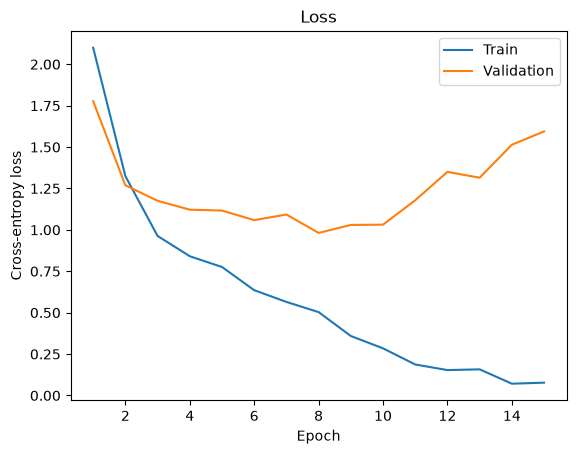

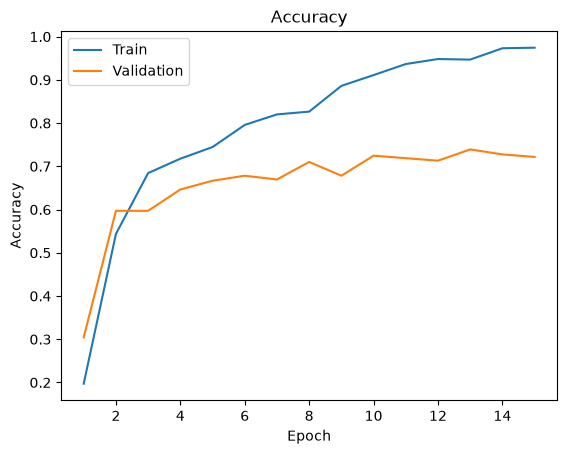

Best validation accuracy: 0.739 at epoch 13 (checkpoint: checkpoints\model_cnn_bs32_lr0.001_epoch13)


In [14]:
# ---- Look at the recorded metrics ----
import matplotlib.pyplot as plt

epochs = range(1, len(history['train_loss']) + 1)

plt.plot(epochs, history['train_loss'], label='Train')
plt.plot(epochs, history['val_loss'], label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss'); plt.legend()
plt.show()

plt.plot(epochs, history['train_acc'], label='Train')
plt.plot(epochs, history['val_acc'], label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()
plt.show()

# Epoch with the highest validation accuracy (+1 because list positions start at 0)
best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
print('Best validation accuracy: {:.3f} at epoch {} (checkpoint: {})'.format(
      max(history['val_acc']), best_epoch,
      get_model_name(model.name, 32, 0.001, best_epoch)))   # use the same batch size / lr as before

# To reload that checkpoint later:
#   model = GestureCNN()
#   model.load_state_dict(torch.load(get_model_name('cnn', 32, 0.001, best_epoch)))


**Training code**

`train(model, train_data, val_data, batch_size, learning_rate, num_epochs)` takes the model object and the usual hyperparameters as arguments. A different setting can therefore be tried with a single call, without editing the training code. Each epoch, the model is trained on the training set in shuffled mini-batches and then evaluated on the validation set. The test set is not used.

The function records the training and validation loss and accuracy for every epoch. Each is averaged over all images in the set, weighting each batch by its size. After every epoch the model weights are saved as a checkpoint named after the hyperparameters, e.g. `checkpoints/model_cnn_bs32_lr0.001_epoch5`, so the best epoch can be reloaded later.

**Loss function:** Used cross-entropy loss (`nn.CrossEntropyLoss`) because this is a multi-class classification problem with 9 mutually exclusive classes (A–I). Cross-entropy compares the predicted probability distribution over the classes with the true class. It gives a large loss when the model is confident and wrong. `nn.CrossEntropyLoss` applies softmax internally, which is more numerically stable than applying softmax separately. For this reason the model outputs raw scores (logits), and the labels are passed as class indices 0–8.

**Optimizer:** Used Adam with a learning rate of 0.001. Adam combines momentum with a separate, adaptive learning rate for each weight. It is therefore less sensitive to the exact choice of learning rate than plain SGD, and usually trains well with its common default of 0.001. This makes it a good starting point for a CNN trained from scratch before any hyperparameter tuning. SGD with momentum is a reasonable alternative that can be compared during the hyperparameter search.

**Other starting values:** a batch size of 32 gives about 49 weight updates per epoch with ~1,560 training images. This is enough updates to make steady progress while keeping each update reasonably stable and memory use low. 15 epochs is a starting point, and the learning curves show whether more epochs are needed.


### Part (c) “Overfit” to a Small Dataset - 5 pt

One way to sanity check our neural network model and training code is to check whether the model is capable
of “overfitting” or “memorizing” a small dataset. A properly constructed CNN with correct training code
should be able to memorize the answers to a small number of images quickly.

Construct a small dataset (e.g. just the images that you have collected). Then show that your model and
training code is capable of memorizing the labels of this small data set.

With a large batch size (e.g. the entire small dataset) and learning rate that is not too high, You should be
able to obtain a 100% training accuracy on that small dataset relatively quickly (within 200 iterations).

In [15]:
# Build the small dataset 
SMALL_SEED = 1

# Training hands that have the complete set of 27 images (all 9 letters x 3 views)
complete_train_hands = sorted(h for h in hands_in['train'] if images_per_hand[h] == 27)
small_hand = random.Random(SMALL_SEED).choice(complete_train_hands)   # fixed seed -> same hand every run

# Indices (into full_dataset) of that hand's images. They all come from split_indices['train'].
small_indices = [i for i in split_indices['train'] if hand_ids[i] == small_hand]
small_dataset = Subset(full_dataset, small_indices)

# Quick checks: right size, only training images, and 3 images of every letter
assert all(hand_to_split[hand_ids[i]] == 'train' for i in small_indices)
small_counts = Counter(classes[samples[i][1]] for i in small_indices)
print('Hand', small_hand, '->', len(small_dataset), 'images')
print('Images per letter:', dict(sorted(small_counts.items())))


Hand 16 -> 27 images
Images per letter: {'A': 3, 'B': 3, 'C': 3, 'D': 3, 'E': 3, 'F': 3, 'G': 3, 'H': 3, 'I': 3}


In [19]:
# ---- Train on the small dataset only ----
# batch_size = the whole small dataset (27), so each epoch is exactly ONE
# iteration (one weight update), and 200 epochs = 200 iterations.
# Same model, loss (cross-entropy) and optimizer (Adam, lr 0.001) as Part 2(b).
# val_data=None: this experiment only checks whether the model can memorize the
# training images. Validation every epoch is not needed (and would be slow).
torch.manual_seed(1000)              # same initial weights every run
small_model = GestureCNN()           # a NEW untrained model from Part 2(a)
small_model.name = 'cnn_small'       # separate checkpoint names from the Part 2(b) model
small_history = train(small_model, small_dataset, None,
                      batch_size=len(small_dataset), learning_rate=0.001, num_epochs=200,
                      print_every=10, checkpoint_every=50)


Epoch  10: train loss 2.0117, train acc 0.370 | 2s
Epoch  20: train loss 0.8665, train acc 0.926 | 4s
Epoch  30: train loss 0.0950, train acc 1.000 | 6s
Epoch  40: train loss 0.0028, train acc 1.000 | 8s
Epoch  50: train loss 0.0002, train acc 1.000 | 10s
Epoch  60: train loss 0.0001, train acc 1.000 | 13s
Epoch  70: train loss 0.0000, train acc 1.000 | 16s
Epoch  80: train loss 0.0000, train acc 1.000 | 18s
Epoch  90: train loss 0.0000, train acc 1.000 | 21s
Epoch 100: train loss 0.0000, train acc 1.000 | 23s
Epoch 110: train loss 0.0000, train acc 1.000 | 26s
Epoch 120: train loss 0.0000, train acc 1.000 | 29s
Epoch 130: train loss 0.0000, train acc 1.000 | 32s
Epoch 140: train loss 0.0000, train acc 1.000 | 35s
Epoch 150: train loss 0.0000, train acc 1.000 | 37s
Epoch 160: train loss 0.0000, train acc 1.000 | 41s
Epoch 170: train loss 0.0000, train acc 1.000 | 45s
Epoch 180: train loss 0.0000, train acc 1.000 | 48s
Epoch 190: train loss 0.0000, train acc 1.000 | 50s
Epoch 200: train

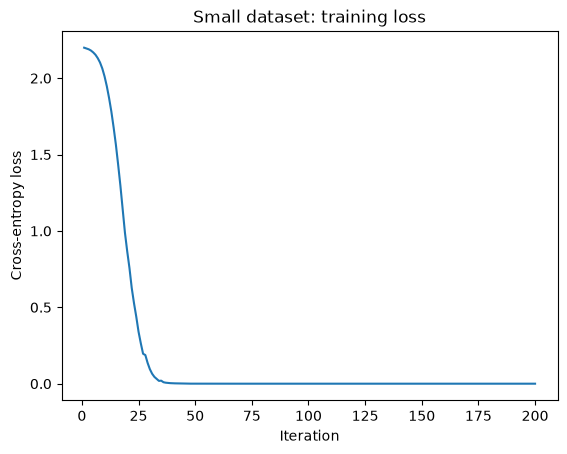

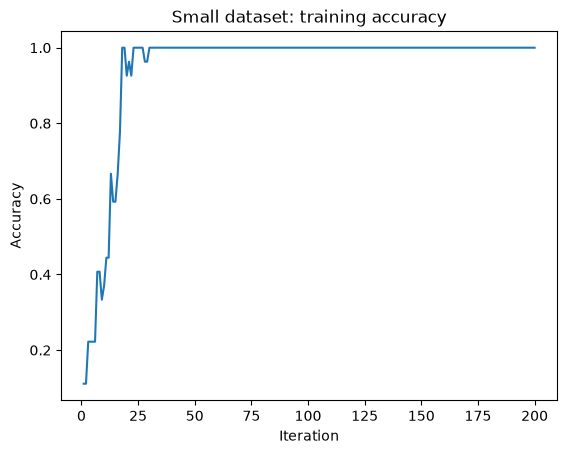

First reached 100% training accuracy at iteration 18
Stayed at 100% from iteration 30 onwards
Final model on the small dataset: loss 0.0000, accuracy 1.000
Same model on the validation set: loss 13.2444, accuracy 0.319


In [20]:
# ---- Did the model memorize the small dataset? ----
import matplotlib.pyplot as plt
iterations = range(1, len(small_history['train_loss']) + 1)

plt.plot(iterations, small_history['train_loss'])
plt.title('Small dataset: training loss'); plt.xlabel('Iteration'); plt.ylabel('Cross-entropy loss')
plt.show()

plt.plot(iterations, small_history['train_acc'])
plt.title('Small dataset: training accuracy'); plt.xlabel('Iteration'); plt.ylabel('Accuracy')
plt.show()

# First iteration where every one of the 27 images was classified correctly.
# (train() measures accuracy just BEFORE each weight update.)
acc = small_history['train_acc']
if 1.0 in acc:
    print('First reached 100% training accuracy at iteration', acc.index(1.0) + 1)
    # Accuracy can briefly drop again after first reaching 100%, so also find the
    # iteration after which it STAYS at 100% (one after the last imperfect iteration).
    imperfect = [i for i, a in enumerate(acc) if a < 1.0]
    print('Stayed at 100% from iteration', imperfect[-1] + 2 if imperfect else 1, 'onwards')
else:
    print('Did not reach 100% training accuracy in', len(acc), 'iterations')

# Re-check the final model on the small dataset in eval mode (after the last update).
criterion = nn.CrossEntropyLoss()
small_loader = DataLoader(small_dataset, batch_size=len(small_dataset))
final_loss, final_acc = evaluate(small_model, small_loader, criterion)
print('Final model on the small dataset: loss {:.4f}, accuracy {:.3f}'.format(final_loss, final_acc))

# For comparison only (NOT used for training): the same model on the validation set,
# i.e. hands it has never seen. Memorizing 27 images of one hand is not expected to generalize.
val_loss, val_acc = evaluate(small_model, DataLoader(val_dataset, batch_size=32), criterion)
print('Same model on the validation set: loss {:.4f}, accuracy {:.3f}'.format(val_loss, val_acc))


**Overfitting a small dataset** 

The small dataset consists of all 27 images of hand 16, with 3 images per letter. The hand was chosen with a fixed random seed from the hands with a complete set of images in the **training** split. The train/validation/test split from Question 1 is unchanged, and no validation or test images are used.

A new, untrained `GestureCNN` was trained on only these 27 images using the same training code, loss function (cross-entropy) and optimizer (Adam, learning rate 0.001). The batch size was the whole small dataset (27), so each epoch is a single iteration (one weight update). The model was trained for 200 iterations, and the training loss and accuracy were recorded at every iteration.

**Result:** training accuracy first reached 100% at iteration 18 and stayed at 100% from iteration 30. The training loss fell from ~2.3 to 0. After training, the model classified 27/27 of the small-dataset images correctly. 

**Interpretation:** this is a sanity check. A CNN with far more parameters (about 828k) than training images should be able to memorize 27 images. If it can, the forward pass, labels, loss, backpropagation and optimizer step are all working together correctly. If it could not, that would point to a bug rather than to a lack of data, for example mismatched labels, a missing `optimizer.zero_grad()`/`step()`, or a learning rate that is too high or too low.

Memorizing is not the same as generalizing. The same model reached only 31.9% on the validation set, which contains hands it has never seen, because 27 images of one hand are far too few to learn features that work for other people's hands.


### 3. Hyperparameter Search [15 pt]

### Part (a) - 3 pt

List 3 hyperparameters that you think are most worth tuning. Choose at least one hyperparameter related to
the model architecture.

### Part (b) - 5 pt

Tune the hyperparameters you listed in Part (a), trying as many values as you need to until you feel satisfied
that you are getting a good model. Plot the training curve of at least 4 different hyperparameter settings.

### Part (c) - 3 pt
Choose the best model out of all the ones that you have trained. Justify your choice.

### Part (d) - 4 pt
Report the test accuracy of your best model. You should only do this step once and prior to this step you should have only used the training and validation data.

### 4. Transfer Learning [15 pt]
For many image classification tasks, it is generally not a good idea to train a very large deep neural network
model from scratch due to the enormous compute requirements and lack of sufficient amounts of training
data.

One of the better options is to try using an existing model that performs a similar task to the one you need
to solve. This method of utilizing a pre-trained network for other similar tasks is broadly termed **Transfer
Learning**. In this assignment, we will use Transfer Learning to extract features from the hand gesture
images. Then, train a smaller network to use these features as input and classify the hand gestures.

As you have learned from the CNN lecture, convolution layers extract various features from the images which
get utilized by the fully connected layers for correct classification. AlexNet architecture played a pivotal
role in establishing Deep Neural Nets as a go-to tool for image classification problems and we will use an
ImageNet pre-trained AlexNet model to extract features in this assignment.

### Part (a) - 5 pt
Here is the code to load the AlexNet network, with pretrained weights. When you first run the code, PyTorch
will download the pretrained weights from the internet.

In [ ]:
import torchvision.models
alexnet = torchvision.models.alexnet(pretrained=True)

The alexnet model is split up into two components: *alexnet.features* and *alexnet.classifier*. The
first neural network component, *alexnet.features*, is used to compute convolutional features, which are
taken as input in *alexnet.classifier*.

The neural network alexnet.features expects an image tensor of shape Nx3x224x224 as input and it will
output a tensor of shape Nx256x6x6 . (N = batch size).

Compute the AlexNet features for each of your training, validation, and test data. Here is an example code
snippet showing how you can compute the AlexNet features for some images (your actual code might be
different):

In [ ]:
# img = ... a PyTorch tensor with shape [N,3,224,224] containing hand images ...
features = alexnet.features(img)

**Save the computed features**. You will be using these features as input to your neural network in Part
(b), and you do not want to re-compute the features every time. Instead, run *alexnet.features* once for
each image, and save the result.

### Part (b) - 3 pt
Build a convolutional neural network model that takes as input these AlexNet features, and makes a
prediction. Your model should be a subclass of nn.Module.

Explain your choice of neural network architecture: how many layers did you choose? What types of layers
did you use: fully-connected or convolutional? What about other decisions like pooling layers, activation
functions, number of channels / hidden units in each layer?

Here is an example of how your model may be called:

In [ ]:
# features = ... load precomputed alexnet.features(img) ...
output = model(features)
prob = F.softmax(output)

### Part (c) - 5 pt
Train your new network, including any hyperparameter tuning. Plot and submit the training curve of your
best model only.

Note: Depending on how you are caching (saving) your AlexNet features, PyTorch might still be tracking
updates to the **AlexNet weights**, which we are not tuning. One workaround is to convert your AlexNet
feature tensor into a numpy array, and then back into a PyTorch tensor.

In [ ]:
tensor = torch.from_numpy(tensor.detach().numpy())

### Part (d) - 2 pt
Report the test accuracy of your best model. How does the test accuracy compare to Part 3(d) without transfer learning?